# KQC JunctionTest2 — SQUID test-pad arrays (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/junction_test2.py` (class `JunctionTest2`, default parameters, chip name "CTest";
© IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/junction_test2.py`; spec `docs/designs/kqc/test_chips.md`, one
notebook per chip). A process / test chip: six `JunctionTestPads` arrays of SQUIDs (Manhattan junctions in the source, Quantcore trilayer SQUIDs here) with stepped junction widths, small (80 µm²) and large (130 µm²) loops. No qubits or resonators.

This notebook **rebuilds** the chip on the Quantcore PDK — not a replica. We distribute the rebuild under GPL-3.0.
The chip is one KQC chip PCell, so most steps of a circuit notebook (launchers, routes, LOM, FEM, iterate) have
nothing to act on here; each says so.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm; the KQC chip cell is placed with `frames_enabled=[]`, so the Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") replaces KQC's frame |
| pattern | `JunctionTest2.build()` | the same KQC cell with its default parameters (except the junction type and the large-loop start width, step 2), so its own `build()` draws every polygon and label |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 (it changes nothing here: there is no circuit to simulate) |
| junctions | KQC Manhattan SQUIDs | Quantcore trilayer SQUIDs (step 2) |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds); the cell keeps it off its structures with `ground_grid_avoidance` | The original wins: `with_grid=True` draws KQC's whole-area grid round the cell, and the cell's `ground_grid_avoidance` keeps it off its six test-pad arrays (fab view, step 14), so no PDK band is added. |
| placement | as drawn by KQC | Centred (50 µm off in x, at the 50 µm tolerance): no shift. |

**Kept exactly:** the chip is KQC's `JunctionTest2` chip PCell placed once in a 10 × 10 mm Designer chip, with
`frames_enabled=[]`, so KQC's `build()` draws every polygon and label but not its ChipFrame; the Designer chip
draws the Quantcore die frame instead. Step 14 XORs it with a stand-alone KQC build, which keeps KQC's frame.

**Simplified:** nothing; there are no internal ports or circuit to rebuild element by element.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/junction_test2")  # step-by-step snapshots (build/ is not kept in the repo)
# Quantcore trilayer SQUIDs in every test pad; the large-loop sweep starts at the PDK minimum finger (0.1 µm)
PDK_SQUIDS = {"junction_type": "Quantcore Squid", "junction_width_large": 0.10}

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip uses the junction rule (its test SQUIDs), the frame, the cheese rule and the fab layer map.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The test SQUIDs from the PDK rule.** Every test SQUID is a Quantcore SQUID (`junction_type="Quantcore Squid"` on
the chip cell): KQC's stepped `junction_width` is the straight finger, the bent finger stays at the PDK 0.6 µm.
KQC's large-loop sweep starts at 0.08 µm, below the PDK minimum finger (0.1 µm), so it starts at 0.10 µm here (the
0.03 µm step is kept); the small-loop sweep keeps 0.15 µm + 0.01 µm steps. `PDK_SQUIDS` (step 1) holds these two
cell parameters; step 9 tabulates the R_n and L_J they give.

## 3 · The die, its frame and the chip cell

`Designer(...)` starts the 10 × 10 mm chip with the name "CTest" (the device ID). The original wins: `with_grid=True` draws KQC's whole-area grid round the cell, and the cell's `ground_grid_avoidance` keeps it off its six test-pad arrays (fab view, step 14), so no PDK band is added.

The whole design is one instance: KQC's `JunctionTest2` chip PCell at the chip origin with `frames_enabled=[]`, so KQC draws
no `ChipFrame` and the Designer chip draws the Quantcore die frame (L dicing markers on 1000/0, 3 × 3 alignment
grids on 1001/0, the chip boundary on 100/0). `center_in_die` then checks that the cell's content sits centred in the
die and moves the cell if it is more than 50 µm off. Centred (50 µm off in x, at the 50 µm tolerance): no shift. Then the design is saved: `junction_test2.json` is what
the DRC, the fab export and `qcc` read.

centring shift (µm): (0.0, 0.0)


<Designer junction_test2: 1 instances, 0 routes, live=False> → examples\designs\kqc\test_chips\junction_test2.json


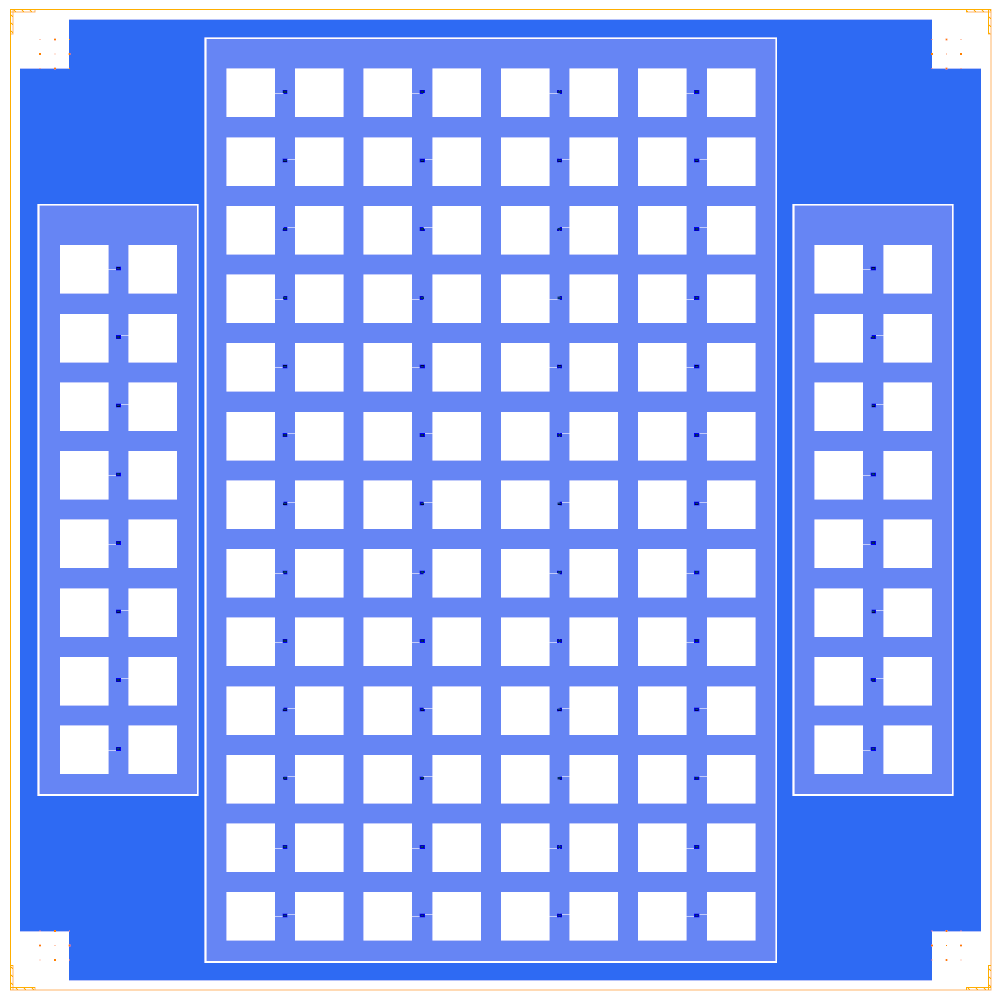

In [4]:
d = Designer("junction_test2", box=(0, 0, 10000, 10000), chip={"name_chip": "CTest", "with_grid": True}, live=LIVE)
d.add("CHIP", "JunctionTest2", at=(0, 0), frames_enabled=[], **PDK_SQUIDS)   # KQC chip PCell, no KQC frame
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "junction_test2.json")
print(d, "→", DESIGN)
snap(d, STEPS / "1_chip.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Pads and the pad rule

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`edge="auto"` on a pad instance). This chip has no pad instances and no launchers (the table below is empty): any probe pads belong to KQC's drawing of the cell, so the rule has nothing to place.

In [5]:
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

## 5 · Components

The one component is the chip cell itself (placed in step 3).

## 6 · Routes

None: there are no RF lines on this chip.

## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** 0 errors and 4 `frame_keepout` warnings: the chip cell's bounding box spans the 10 × 10 mm chip and so overlaps the four corner marker areas; nothing the cell draws sits on the dicing L's or the alignment grids (the frame-corner snapshot shows it). No PDK design warning; `pdk_report` gives KQC's grid ("the original design's own"), the content 50 µm off in x and no junction types (the test SQUIDs sit inside the cell's `JunctionTestPads`, which the report does not count).

In [6]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 4 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `frame_keepout` | 4 | CHIP overlaps the marker_area_sw |

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (-50, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit from the components' LOM models. No component here has one (the
chip is a process test structure), so the netlist is ground only.

In [7]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

**1 nodes · 0 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |

| branch | type | nodes | estimate |
|---|---|---|---|

**Unconnected ports:** none

{'nodes': 0, 'branches': 0, 'controls': 0, 'unconnected': 0}


## 9 · LOM simulation — not applicable; the junction table instead

There are no modes to simulate. What this chip measures is each test SQUID's R_n (at room temperature, on a probe
station), so the useful numbers are the R_n and L_J the PDK junction rule gives each stepped finger: two junctions
in parallel per SQUID (`circuit.bridges.junction_from_fingers`: Nb Δ = 1.4 meV, R_n·A = 13.5 kΩ·µm² assumed). The
last column counts the SQUIDs inside the PDK's 40–50 kΩ window.

In [8]:
from quantcore_circuits.circuit.bridges import junction_from_fingers
from quantcore_circuits.pdk import get_pdk
from kqcircuits.chips.junction_test2 import JunctionTest2

PROC = get_pdk().junction                         # Nb Δ 1.4 meV, R_n·A 13.5 kΩ·µm² (assumed), bent finger 0.6 µm


def squid_table(squids):
    p = JunctionTest2()
    heights = [6000, 9400, 9400, 9400, 9400, 6000]
    start = {"small": squids.get("junction_width_small", p.junction_width_small),
             "large": squids.get("junction_width_large", p.junction_width_large)}
    step = {"small": p.junction_width_step_increment_small, "large": p.junction_width_step_increment_large}
    idx = {"small": 0, "large": 0}
    lo, hi = PROC.rn_target_kohm
    rows = ["| array | loop | SQUIDs | straight finger (µm) | R_n per SQUID (kΩ) | L_J per SQUID (nH) | in 40–50 kΩ |",
            "|---|---|---|---|---|---|---|"]
    total = 0
    for j, (loop, h) in enumerate(zip(p.pads_loop, heights), start=1):
        n = int(h // (p.pad_spacing + p.pad_width))
        ws = [start[loop] + (idx[loop] + k) * step[loop] for k in range(n)]
        idx[loop] += n
        v = [junction_from_fingers(w, PROC.bent_finger_um, n=2) for w in ws]
        inside = sum(lo <= x.rn_kohm <= hi for x in v)
        total += inside
        rows.append(f"| {j} | {loop} ({p.large_loop_area if loop == 'large' else p.small_loop_area:g} µm²) | {n} | "
                    f"{ws[0]:.2f} … {ws[-1]:.2f} | {v[0].rn_kohm:.1f} … {v[-1].rn_kohm:.1f} | "
                    f"{v[0].lj_nH:.2f} … {v[-1].lj_nH:.2f} | {inside} |")
    return "\n".join(rows), total


table, n_in = squid_table(PDK_SQUIDS)
display(Markdown(table + f"\n\n**{n_in} SQUIDs inside the window.**"))

| array | loop | SQUIDs | straight finger (µm) | R_n per SQUID (kΩ) | L_J per SQUID (nH) | in 40–50 kΩ |
|---|---|---|---|---|---|---|
| 1 | large (130 µm²) | 8 | 0.10 … 0.31 | 112.5 … 36.3 | 16.84 … 5.43 | 2 |
| 2 | large (130 µm²) | 13 | 0.34 … 0.70 | 33.1 … 16.1 | 4.95 … 2.41 | 0 |
| 3 | small (80 µm²) | 13 | 0.15 … 0.27 | 75.0 … 41.7 | 11.22 … 6.24 | 5 |
| 4 | small (80 µm²) | 13 | 0.28 … 0.40 | 40.2 … 28.1 | 6.01 … 4.21 | 1 |
| 5 | small (80 µm²) | 13 | 0.41 … 0.53 | 27.4 … 21.2 | 4.11 … 3.18 | 0 |
| 6 | large (130 µm²) | 8 | 0.73 … 0.94 | 15.4 … 12.0 | 2.31 … 1.79 | 0 |

**8 SQUIDs inside the window.**

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: nothing to export: the chip has no sim groups (a process structure has nothing for a C-matrix or
eigenmode solve), so `send_fem_jobs` writes no job.

In [9]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

0 job(s) exported; RUN_FEM is False, nothing solved.


No sim groups: no FEM job.

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [10]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM jobs.

## 12 · Change one property and re-evaluate

There is no simulation to re-run, but the sweep is a design choice: it decides how many SQUIDs land in the PDK
window. Start the large-loop sweep at 0.40 µm instead of 0.10 µm (the same 0.03 µm step) and count again. The chip
itself is not rebuilt (the change is on the table's parameters only).

In [11]:
table2, n_in2 = squid_table(dict(PDK_SQUIDS, junction_width_large=0.40))
display(Markdown(f"**Large-loop start 0.10 → 0.40 µm:** {n_in} → {n_in2} SQUIDs in the 40–50 kΩ window\n\n" + table2))

**Large-loop start 0.10 → 0.40 µm:** 8 → 6 SQUIDs in the 40–50 kΩ window

| array | loop | SQUIDs | straight finger (µm) | R_n per SQUID (kΩ) | L_J per SQUID (nH) | in 40–50 kΩ |
|---|---|---|---|---|---|---|
| 1 | large (130 µm²) | 8 | 0.40 … 0.61 | 28.1 … 18.4 | 4.21 … 2.76 | 0 |
| 2 | large (130 µm²) | 13 | 0.64 … 1.00 | 17.6 … 11.2 | 2.63 … 1.68 | 0 |
| 3 | small (80 µm²) | 13 | 0.15 … 0.27 | 75.0 … 41.7 | 11.22 … 6.24 | 5 |
| 4 | small (80 µm²) | 13 | 0.28 … 0.40 | 40.2 … 28.1 | 6.01 … 4.21 | 1 |
| 5 | small (80 µm²) | 13 | 0.41 … 0.53 | 27.4 … 21.2 | 4.11 … 3.18 | 0 |
| 6 | large (130 µm²) | 8 | 1.03 … 1.24 | 10.9 … 9.1 | 1.63 … 1.36 | 0 |

## 13 · Build and export

**The design file.** `junction_test2.json` (saved in step 3) is the whole design: `qcc build
examples/designs/kqc/test_chips/junction_test2.json` rebuilds `build/junction_test2.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0,
and the frame (100/0, 1000/0, 1001/0). In this run: 1/0 200 995 polygons, 3/0 197 928, the trilayer fingers 2/0 and 4/0 68 polygons each, 50–53/0 272 each; cheese source `build`, 200 992 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/junction_test2.json` writes the complete file.

In [12]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 200995 |
| 2/0 | JJ_STRAIGHT | 68 |
| 3/0 | M3 | 197928 |
| 4/0 | JJ_BENT | 68 |
| 50/0 | HSQ | 272 |
| 51/0 | SPACER_1 | 272 |
| 52/0 | SPACER_2 | 272 |
| 53/0 | SPACER_3 | 272 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 200992 holes on the mask.

→ `build/junction_test2_fab.oas`

## 14 · Snapshots

The full chip; a zoom on the pad; the die frame's south-west corner (dicing L on 1000/0,
3 × 3 alignment grid on 1001/0); and one test-pad pair in the **fab view** (the mask from step 13). The chip
boundary 100/0 is drawn as an outline.

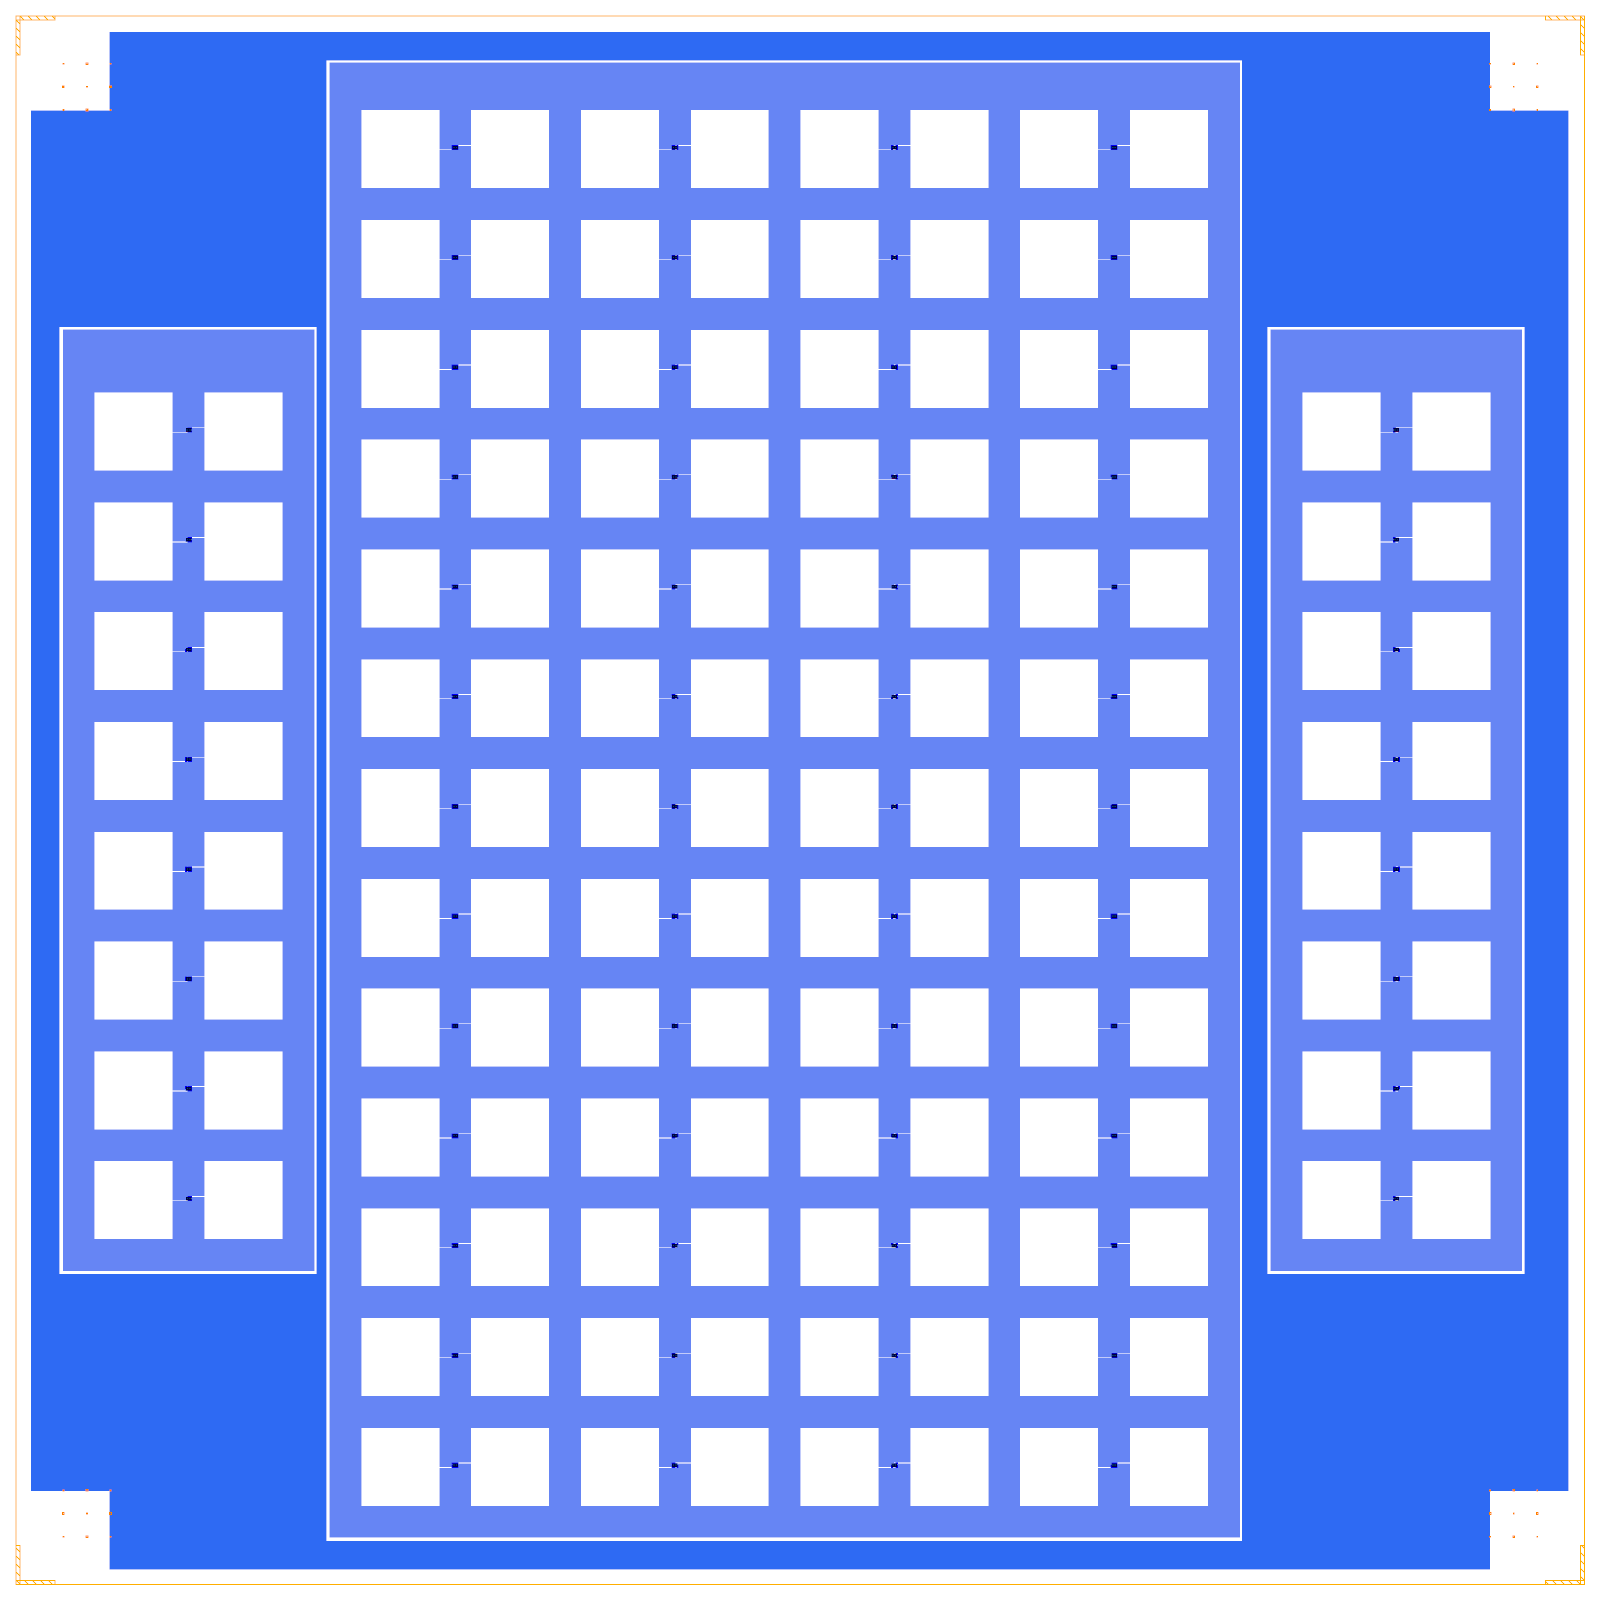

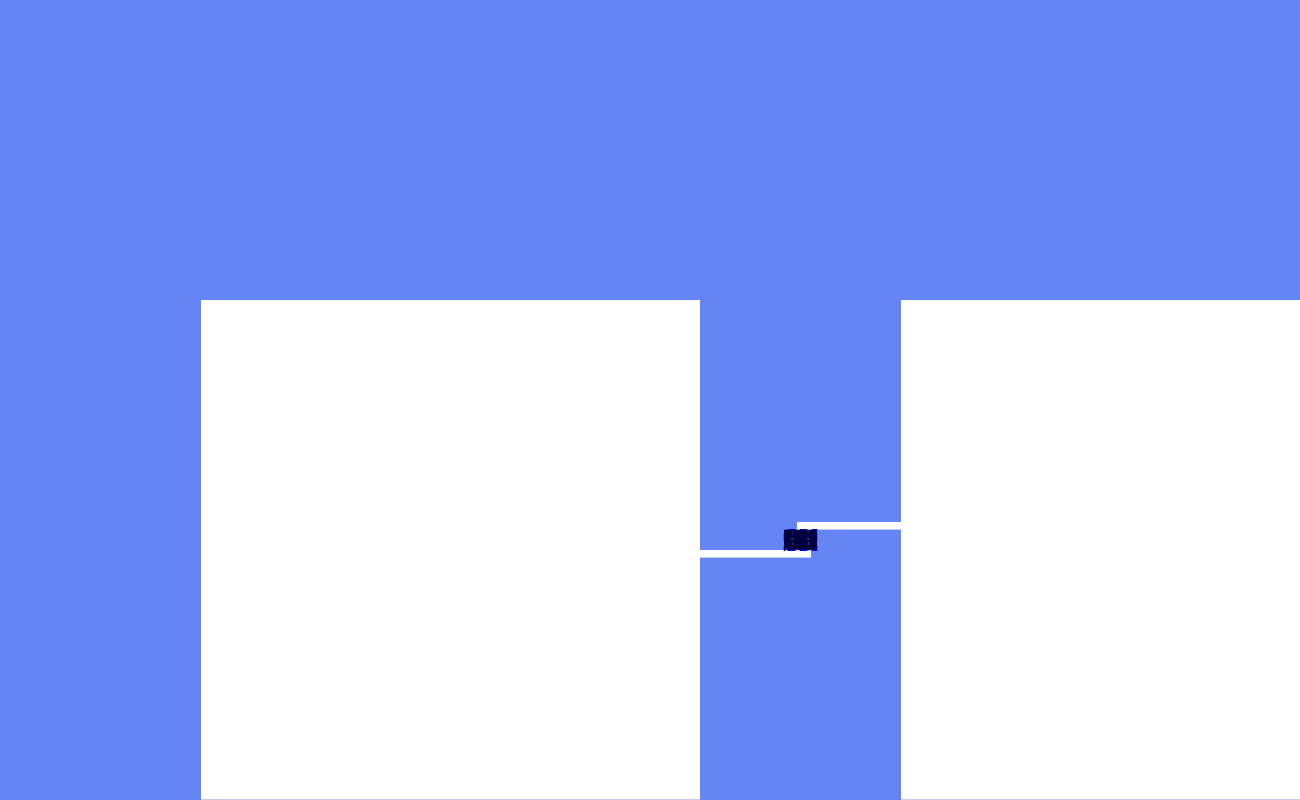

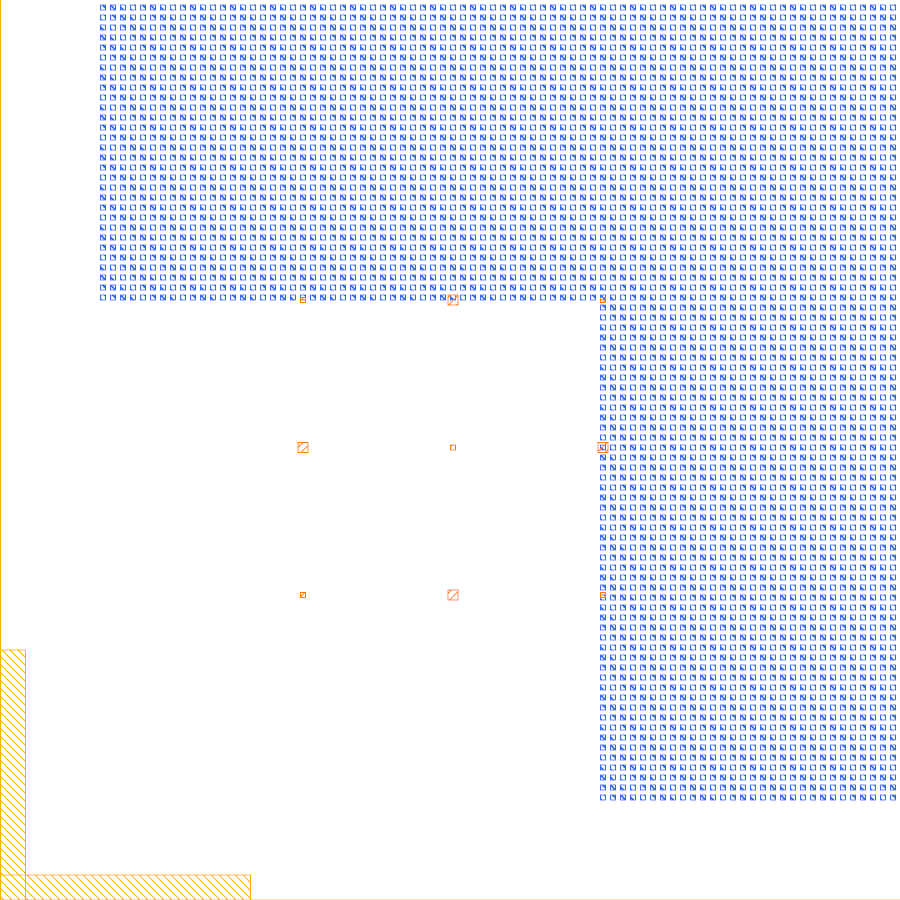

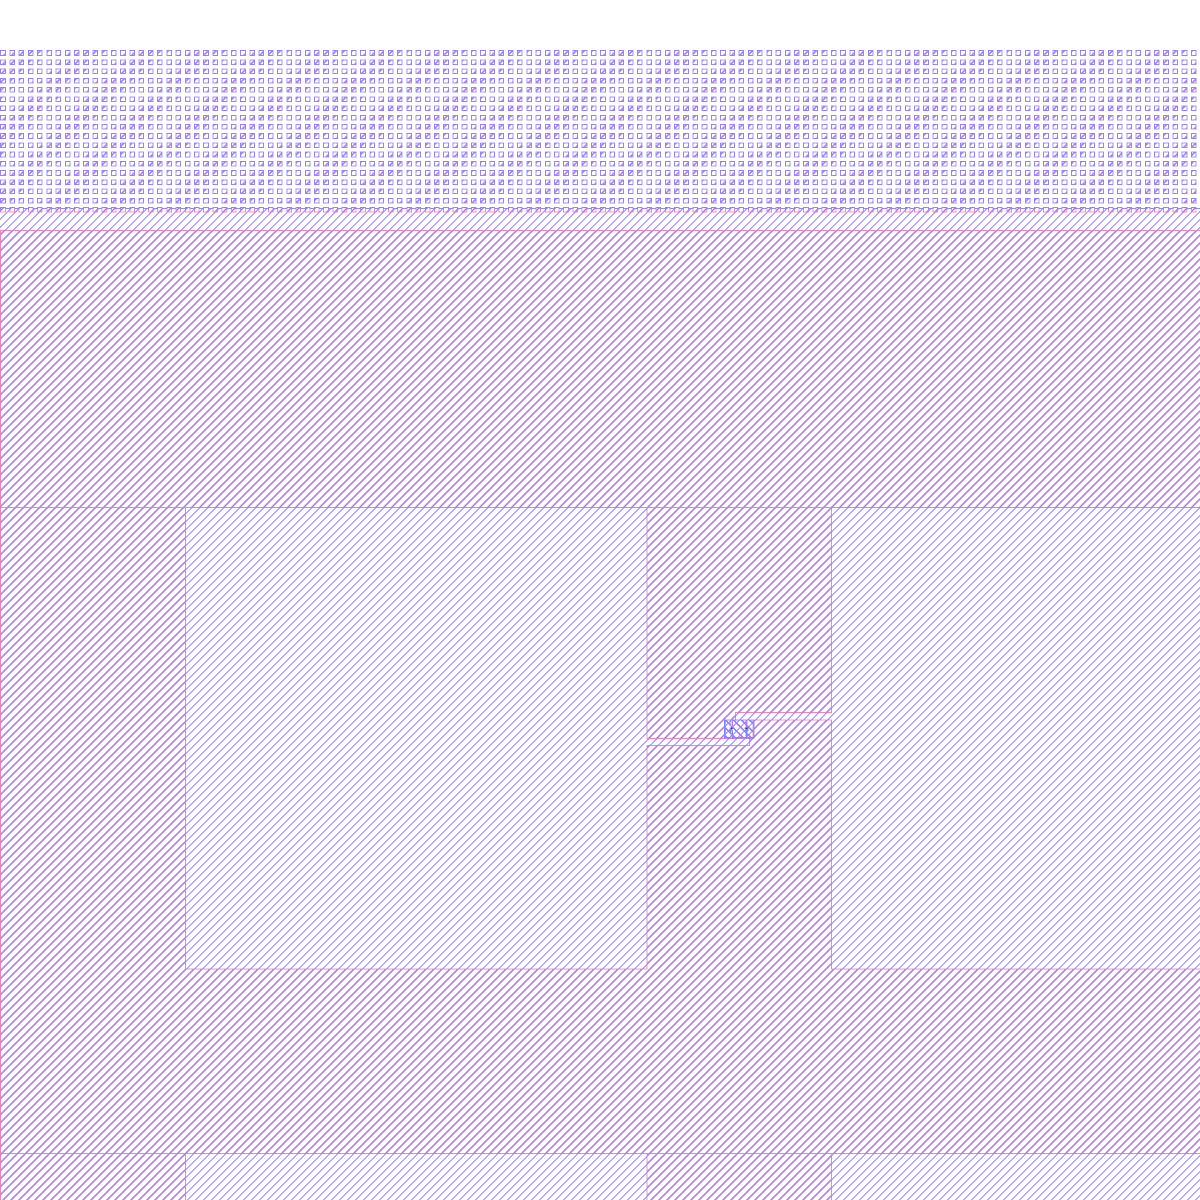

In [13]:
X0, Y0 = d.data["instances"]["CHIP"]["place"]["at"]   # the cell's origin (after the centring shift)
show_snapshot(d, OUT / "junction_test2.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "junction_test2_pad.png", box=(X0 + 2000, Y0 + 8900, X0 + 3300, Y0 + 9700), size=(1300, 800), width=420)
show_snapshot(d, OUT / "junction_test2_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "junction_test2_fab.oas", OUT / "junction_test2_fab.png", box=(X0 + 2000, Y0 + 8900, X0 + 3300, Y0 + 9700), size=(1200, 1200), width=420);

**Reference: XOR with the source.** KQC's `JunctionTest2` built stand-alone (with KQC's own frame), XOR-ed layer by layer
with this build (`refpoints` and the `instance_names` label layer are annotation and are skipped). **The rebuild is
expected to differ** by design in the frame (KQC's ChipFrame vs the Quantcore die frame), the junction layers (Manhattan → trilayer SQUIDs) and the ground grid (KQC's stand-alone build has none). A
reference, not a pass/fail check.

| layer | XOR area (µm²) |
|---|---|
| 1t1_base_metal_addition (131/1) | 4.66e+04 |
| 1t1_ground_grid_avoidance (133/1) | 1.38e+07 |
| 1t1_SIS_junction (136/1) | 3.27e+04 |
| 1t1_SIS_junction_2 (139/1) | 3.91e+04 |
| 1t1_base_metal_gap_wo_grid (130/1) | 8.73e+06 |
| 1t1_base_metal_gap_for_EBL (134/1) | 8.7e+06 |
| 1t1_SIS_shadow (137/1) | 2.8e+04 |
| 1t1_chip_dicing (158/1) | 2.68e+05 |
| 1t1_airbridge_pads (146/1) | 5.4e+05 |
| 1t1_airbridge_flyover (147/1) | 2.81e+05 |

**Total XOR area: 3.24e+07 µm²**

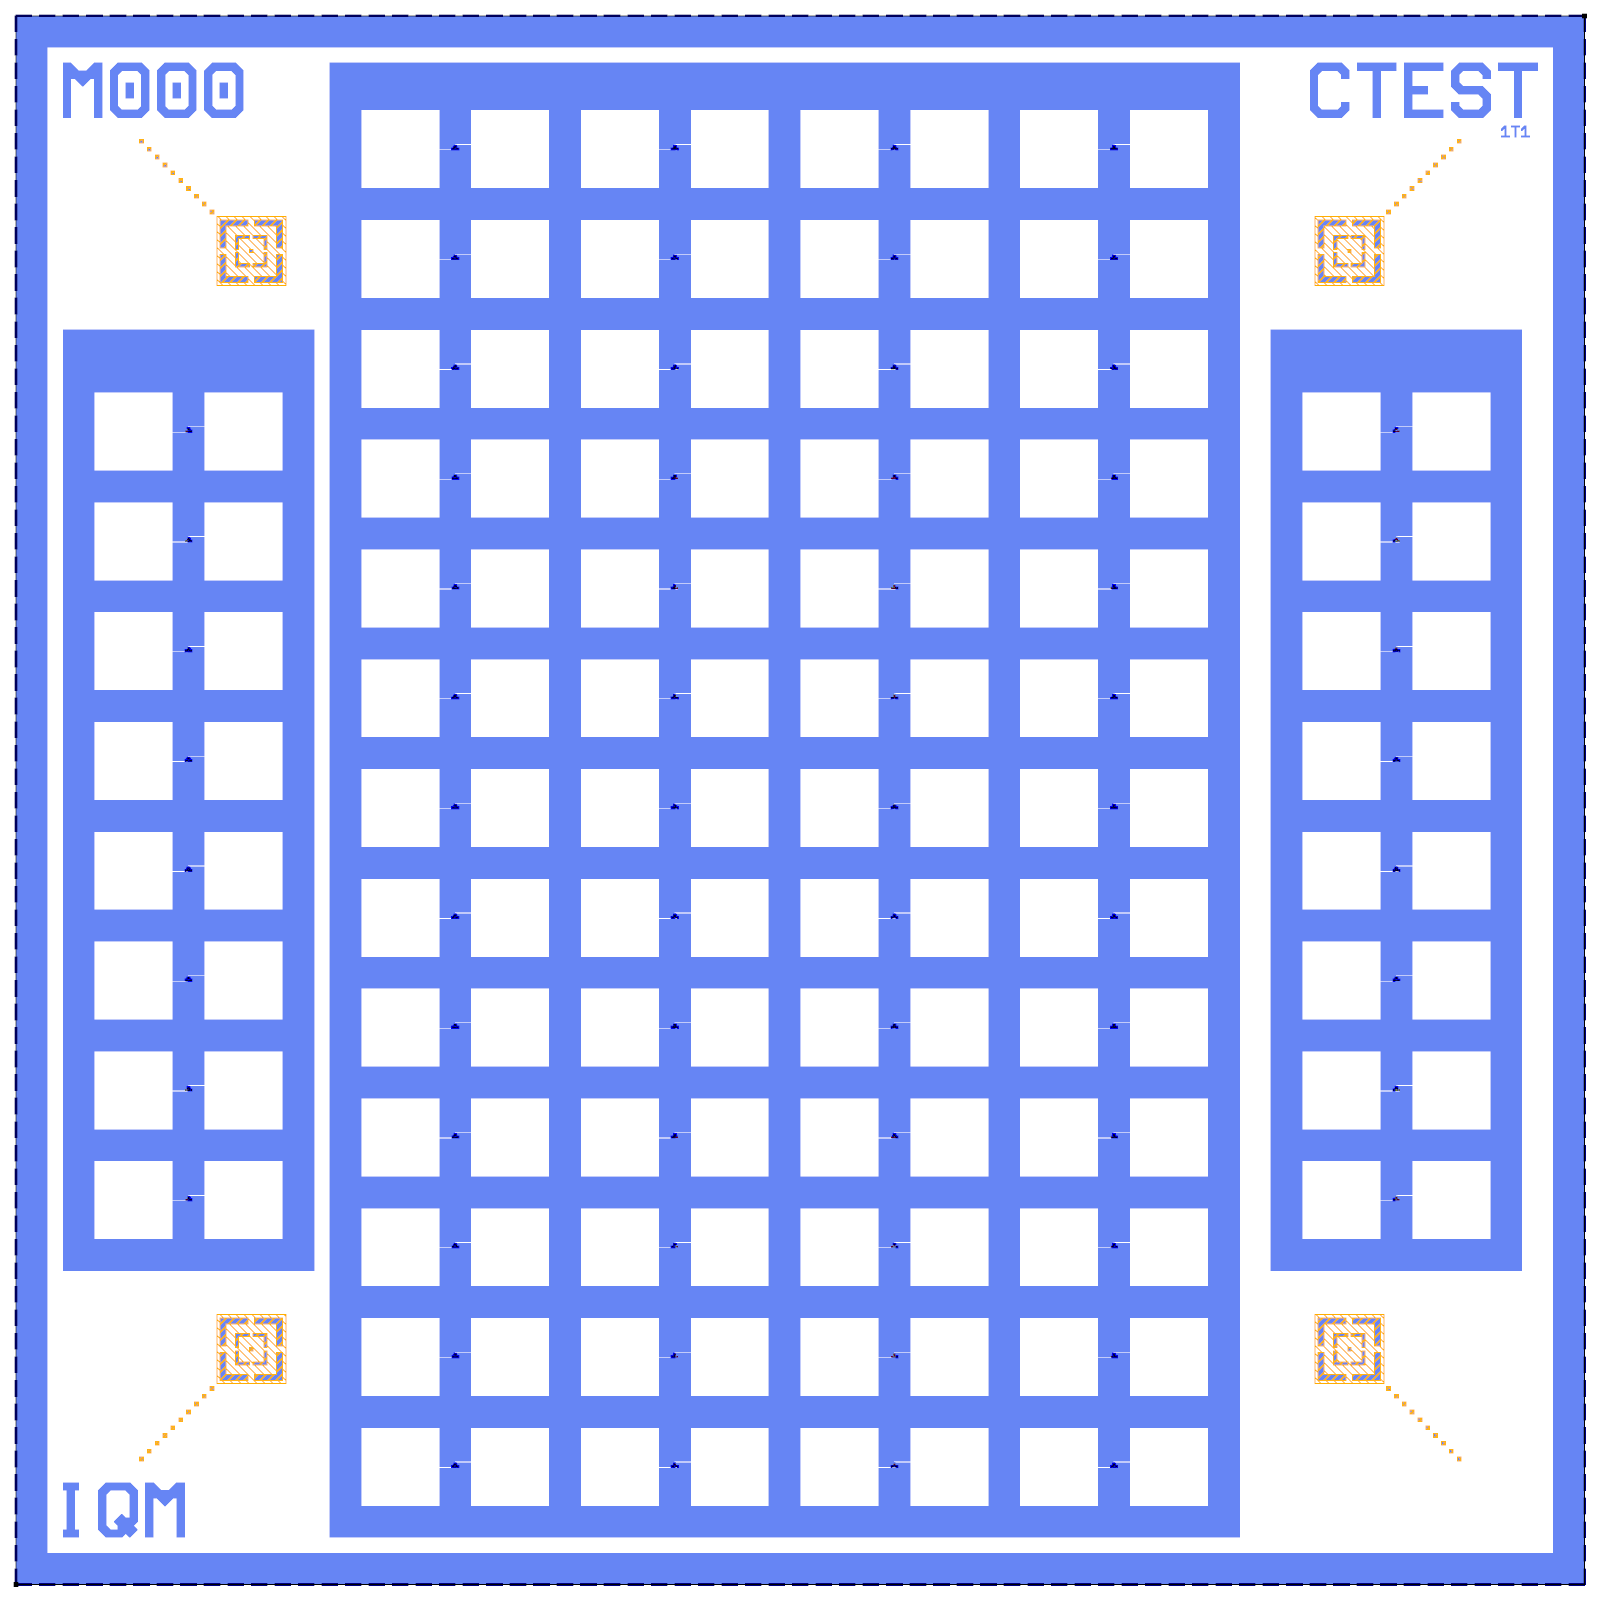

In [14]:
import klayout.db as kdb
from kqcircuits.chips.junction_test2 import JunctionTest2
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
ref_top = ref.create_cell("ref")
ref_top.insert(pya.DCellInstArray(JunctionTest2.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "junction_test2_kqc_original.oas"))
ly = kdb.Layout()
ly.read(str(d.out))
top = ly.top_cell()
by_name = {ly.get_info(i).name: i for i in ly.layer_indexes()}
rows, total = ["| layer | XOR area (µm²) |", "|---|---|"], 0.0
for li in ref.layer_indexes():
    info = ref.get_info(li)
    a = kdb.Region(ref_top.begin_shapes_rec(li)).merged()
    if a.is_empty() or info.name in ("refpoints", "instance_names"):
        continue
    b = kdb.Region(top.begin_shapes_rec(by_name[info.name])).merged() if info.name in by_name else kdb.Region()
    x = (a ^ b).area() * ref.dbu ** 2
    total += x
    rows.append(f"| {info.name} ({info.layer}/{info.datatype}) | {x:.3g} |")
display(Markdown("\n".join(rows) + f"\n\n**Total XOR area: {total:.3g} µm²**"))
snap_file(Path("build") / "junction_test2_kqc_original.oas", OUT / "junction_test2_kqc.png", box=(-100, -100, 10100, 10100), width=420);

**Here:** the XOR (3.2 × 10⁷ µm²) is KQC's frame and the junctions: KQC draws Manhattan SQUIDs (SIS layers 136/137/139, 3–4 × 10⁴ µm² each), the rebuild trilayer SQUIDs (base-metal addition 4.7 × 10⁴ µm²); the base etch differs by 8.73 × 10⁶ µm², the frame's 8.63 × 10⁶ plus the SQUID openings.

## 15 · Summary

| | |
|---|---|
| **matches the source** | the whole `JunctionTest2` cell (KQC's own `build()`); the junction sweep (from 0.10 µm on the large loops) |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the PDK fab layer map; KQC's grid round the arrays (200 992 holes); trilayer SQUIDs with the large-loop sweep from 0.10 µm (8 of the 68 SQUIDs in the 40–50 kΩ window) |
| **not applicable** | the pad rule (no pad instances), routes, LOM, FEM |
| **PDK design warnings** | as listed in step 7 |
| **FEM** | no sim groups, no jobs |